In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


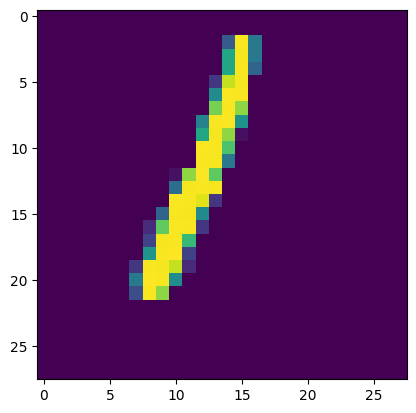

In [4]:
plt.imshow(df.iloc[38, 1:].values.reshape(28,28,))

In [5]:
df.shape

(210000, 785)

In [6]:
# Train_test_Split

x = df.drop('label', axis = 'columns')
y = df.drop(x, axis = 'columns')

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [9]:
# from sklearn.neighbors import KNeighborsClassifier

In [10]:
# knn = KNeighborsClassifier()

In [11]:
# knn.fit(x_train, y_train)

In [12]:
# pred = knn.predict(x_test)

# See, in such algorithms like KNN, which requires lot of computations, will take high time to predict when 
# we have large no_of columns (here 784). 

# This is the reason we use PCA to reduce the dimensions of the dataset

In [13]:
# The most imp thing is to use PCA, we need to scale our data.

from sklearn.preprocessing import StandardScaler

In [14]:
ss = StandardScaler()

x_train = ss.fit_transform(x_train)
x_test = ss.transform(x_test)

In [15]:
x_train.shape

(168000, 784)

In [16]:
# Using PCA

from sklearn.decomposition import PCA

In [13]:
pca = PCA(n_components = 100)

In [14]:
x_train_trans = pca.fit_transform(x_train)
x_test_trans = pca.transform(x_test)

In [15]:
x_train.shape    # See, columns reduced from 784 to 100

(168000, 100)

# Training the model.

Now it won't take high time in prediction

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [42]:
knn = KNeighborsClassifier(n_jobs = -1)

In [43]:
knn.fit(x_train_trans, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


KNeighborsClassifier(n_jobs=-1)

In [44]:
pred = knn.predict(x_test_trans)

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [46]:
acc = accuracy_score(y_test, pred)

acc

0.9915

In [47]:
cr = classification_report(y_test, pred)

print(cr)

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      4128
           1       1.00      1.00      1.00      4671
           2       0.99      0.99      0.99      4145
           3       0.99      0.99      0.99      4373
           4       0.99      0.99      0.99      4081
           5       0.99      0.99      0.99      3799
           6       0.99      1.00      1.00      4219
           7       0.99      0.99      0.99      4391
           8       0.99      0.99      0.99      4040
           9       0.98      0.99      0.99      4153

    accuracy                           0.99     42000
   macro avg       0.99      0.99      0.99     42000
weighted avg       0.99      0.99      0.99     42000



In [48]:
cm = confusion_matrix(y_test, pred)

print(cm)

[[4102    0    0    0    0    0   16    3    4    3]
 [   0 4657    8    0    0    0    0    0    3    3]
 [   3    0 4113    8    0    3    0   12    6    0]
 [   0    0    0 4344    0   16    0    0   13    0]
 [   3    0    6    3 4031    0    3    6    0   29]
 [   0    0    0   14    3 3767    6    0    6    3]
 [   0    3    3    0    3    8 4202    0    0    0]
 [   0    0    6    3   12    0    0 4330    3   37]
 [  13    6    4   12    7    6    0    3 3986    3]
 [   0    0    3    9   21    0    0    9    0 4111]]


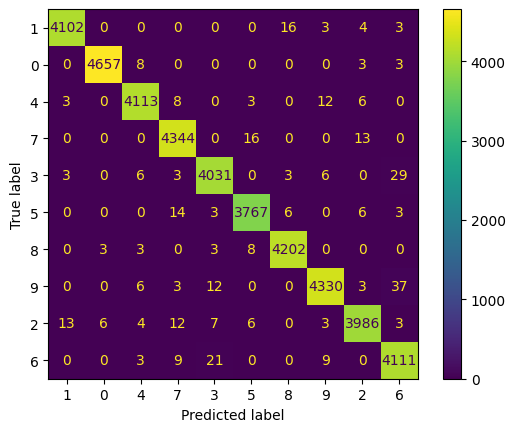

In [49]:
disp = ConfusionMatrixDisplay(cm, display_labels = df.label.unique())

disp.plot()

# Hyperparameter tuning KNN

In [18]:
n_neighbors = [3, 5, 7, 9, 11, 15, 17, 21]
weights = ['uniform', 'distance']

params_grid = {
    'n_neighbors': n_neighbors,
    'weights': weights
}

In [20]:
x_train.shape

(168000, 100)

In [15]:
from sklearn.model_selection import GridSearchCV

In [22]:
grid = GridSearchCV(estimator = knn,
                    param_grid = params_grid,
                    scoring = 'accuracy',
                    cv = 2,
                    n_jobs = -1,
                    verbose = 1
                    )

In [23]:
grid.fit(x_train_trans, y_train)

# Here we have 168000 rows with 784 columns in x_train. So, it will take hver high time to train the model

Fitting 2 folds for each of 16 candidates, totalling 32 fits


C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


GridSearchCV(cv=2, estimator=KNeighborsClassifier(n_jobs=-1), n_jobs=-1,
             param_grid={'n_neighbors': [3, 5, 7, 9, 11, 15, 17, 21],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy', verbose=1)

In [27]:
grid.best_params_

{'n_neighbors': 9, 'weights': 'distance'}

In [28]:
grid.best_score_

0.9942142857142857

In [32]:
best_model = grid.best_estimator_

In [33]:
pred = best_model.predict(x_test_trans)

In [34]:
pred

array([1, 0, 9, ..., 8, 4, 8], dtype=int64)

In [22]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [38]:
acc = accuracy_score(y_test, pred)

acc

0.9992857142857143

In [39]:
cr = classification_report(y_test, pred)

print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4128
           1       1.00      1.00      1.00      4671
           2       1.00      1.00      1.00      4145
           3       1.00      1.00      1.00      4373
           4       1.00      1.00      1.00      4081
           5       1.00      1.00      1.00      3799
           6       1.00      1.00      1.00      4219
           7       1.00      1.00      1.00      4391
           8       1.00      1.00      1.00      4040
           9       1.00      1.00      1.00      4153

    accuracy                           1.00     42000
   macro avg       1.00      1.00      1.00     42000
weighted avg       1.00      1.00      1.00     42000



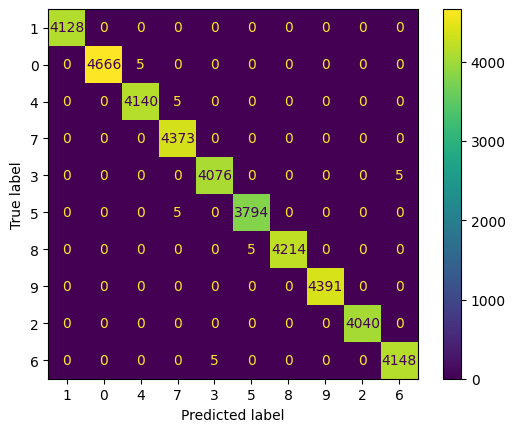

In [40]:
cm = confusion_matrix(y_test, pred)

disp = ConfusionMatrixDisplay(cm, display_labels = df.label.unique())

disp.plot()

# See, after hyperparameter tuning, it is performing more better

# Now, the question is, how many n_compoments we should select?

`Explained variance_ratio` tells us, how much information is captured by each Principle component.

For eg, `n_componnents = 1`, will give one component and tell us how much info it is capturing <br>
`n_components = 5` will give us 5 components and tell how how much info each component is capturing <br>

We should `select` that `n_components`, where `sum of Principle component is >=95`

In [63]:
pca.explained_variance_ratio_

# Explained variance_ratio tells us, how much information is captured by each Principle component.

# For eg, n_componnents = 1, will give one component and tell us how much info it is capturing
# n_comp = 5 will give us 5 components and tell how how much info each component is capturing

# Here, 0.05539 is ratio of info 1st PC is capturing and so onn

array([0.05539799, 0.0396717 , 0.03755081, 0.02800732, 0.02470288,
       0.02168533, 0.01970342, 0.01794518, 0.01522297, 0.01416735,
       0.01399627, 0.01246628, 0.01158206, 0.0108848 , 0.01041481,
       0.01026343, 0.00998053, 0.00947394, 0.00934435, 0.00918861,
       0.00900423, 0.00867288, 0.00832484, 0.00803901, 0.00780043,
       0.00764698, 0.0074432 , 0.00732429, 0.00705381, 0.00702039,
       0.00701463, 0.00658776, 0.00649637, 0.0064208 , 0.00632281,
       0.00611805, 0.00602745, 0.00595984, 0.00590489, 0.0056871 ,
       0.00557102, 0.00555167, 0.00542338, 0.00537788, 0.00530572,
       0.00521671, 0.00517326, 0.00509771, 0.00499424, 0.00493135,
       0.00485438, 0.00475414, 0.00471208, 0.00461799, 0.00453086,
       0.00447257, 0.00439384, 0.00434449, 0.00428075, 0.0042235 ,
       0.00414844, 0.00408988, 0.00405673, 0.00398632, 0.00397247,
       0.0038942 , 0.00382901, 0.00374527, 0.0037209 , 0.0036433 ,
       0.00360637, 0.00353762, 0.00347991, 0.00344707, 0.00337

# Let's see which n_components is giving `ratio>=95`

In [18]:
pca = PCA(n_components = None)

# n_components = Non will create PC = no_of_columns
# Here we have 784 columns, so 784 PC

In [20]:
x_train_trans = pca.fit_transform(x_train)

In [28]:
pca.explained_variance_ratio_.shape

# See, we have 784 PC

(784,)

In [30]:
exp_var_ratio = pca.explained_variance_ratio_

In [32]:
# Now let's see which n_components is giving infp >=95

cumsum = np.cumsum(exp_var_ratio)

# cumsum() retruns cumulative sum
# For eg: [1, 2, 3, 4, 5]
# cumsum = [1, 3, 6, 10, 15]

In [52]:
np.argmax(cumsum>0.95)
# This returns index where value is 0.95
# Hence n_components = 278+1 bcz index starts from 0

278

In [53]:
# See below chart, it will also show 278 as 0.95 variance

Text(0, 0.5, 'Explained variance')

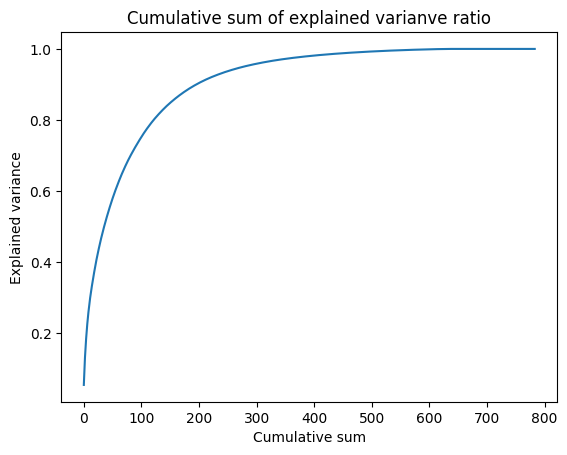

In [72]:
plt.plot(cumsum)
plt.title('N_components of Cumulative Sum')
plt.xlabel('Cumulative sum')
plt.ylabel('Explained variance')

# Hence, 279 is the best n_components.

In [17]:
pca = PCA(n_components = 279)

x_train_trans = pca.fit_transform(x_train)
x_test_trans = pca.transform(x_test)

print(x_train_trans.shape)
print(x_test_trans.shape)

(168000, 279)
(42000, 279)


In [19]:
from sklearn.neighbors import KNeighborsClassifier

In [20]:
# Create KNN object
knn = KNeighborsClassifier(n_neighbors = 9,
                              weights = 'distance',
                              n_jobs = -1)


knn.fit(x_train_trans, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


KNeighborsClassifier(n_jobs=-1, n_neighbors=9, weights='distance')

In [21]:
pred = knn.predict(x_test_trans)

In [27]:
from sklearn.model_selection import cross_val_score

In [32]:
# Perform 5-fold cross validation

acc = cross_val_score(estimator = knn, X = x_train_trans, y = y_train, cv = 5, n_jobs = -1)
acc.mean()

0.999

In [33]:
acc2 = accuracy_score(y_test, pred)
acc2

0.9992857142857143

In [34]:
cr = classification_report(y_test, pred)

print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4128
           1       1.00      1.00      1.00      4671
           2       1.00      1.00      1.00      4145
           3       1.00      1.00      1.00      4373
           4       1.00      1.00      1.00      4081
           5       1.00      1.00      1.00      3799
           6       1.00      1.00      1.00      4219
           7       1.00      1.00      1.00      4391
           8       1.00      1.00      1.00      4040
           9       1.00      1.00      1.00      4153

    accuracy                           1.00     42000
   macro avg       1.00      1.00      1.00     42000
weighted avg       1.00      1.00      1.00     42000



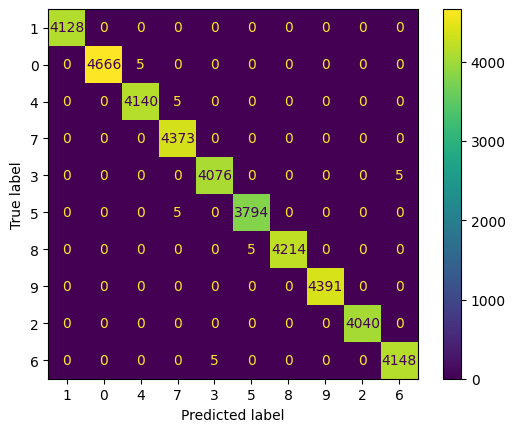

In [35]:
cm = confusion_matrix(y_test, pred)

disp = ConfusionMatrixDisplay(cm, display_labels = df.label.unique())

disp.plot()

# Session Complete